In [1]:
##------------Imports, paths------------

import os
import zipfile
import sqlite3
import requests
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import geopandas as gpd
import plotly.graph_objects as go
import plotly.figure_factory as ff
import matplotlib.pyplot as plt

nrows=500000
source_url = "https://www.fs.usda.gov/rds/archive/products/RDS-2013-0009.7/RDS-2013-0009.7_Data_Format4_SQLITE.zip"    
local_dir = "wildfire_7th_edition_data"
os.makedirs(local_dir, exist_ok=True)
zip_path = os.path.join(local_dir, "us_wildfires_v7.zip")

In [2]:
##------------Data download - run one time only------------

if 1==1:
    print("📡 Initializing browser emulation handshake with U.S. Forest Service...")
    # 1. BYPASS 403 FORBIDDEN: Fake a verified user desktop connection header
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
    }
    # 2. STREAM SECURE TRANSFER: Download block-by-block to keep memory low
    if not os.path.exists(zip_path):
        print("📥 Streaming 7th Edition database (~219MB compressed package)... Please wait.")
        with requests.get(source_url, headers=headers, stream=True) as response:
            response.raise_for_status()
            with open(zip_path, 'wb') as f:
                for chunk in response.iter_content(chunk_size=16384):
                    if chunk:
                        f.write(chunk)
        print("✅ Download finished completely.")
        
    # 3. EXTRACTION SEQUENCE
    print("🔓 Unpacking compressed archive contents...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(local_dir)

if 1==1: 
    # 4. READ metadata file    
    data_dir = local_dir+'/Data/'
    df_meta = pd.read_csv(data_dir+'_variable_descriptions.csv', keep_default_na=False)
    print(df_meta)

    # 5. READ data file
    db_path = data_dir+'FPA_FOD_20260615.sqlite'
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()

    # 6. List all available tables within the master catalog schema
    cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
    print("📁 Available Tables in Database:")
    tables = cursor.fetchall()
    for t in tables:
        print(f"   ↳ {t[0]}")

    # 7. Inspect column headers and data types inside the main 'Fires' table
    cursor.execute("PRAGMA table_info(Fires);")
    print("\n📊 Column Schema Details for 'Fires' Table:")
    columns = cursor.fetchall()
    for col in columns:
        # col[1] = Column Name, col[2] = Data Type (TEXT, REAL, INT)
        print(f"   ↳ Header: {col[1]:<20} | Type: {col[2]}")


📡 Initializing browser emulation handshake with U.S. Forest Service...
🔓 Unpacking compressed archive contents...
                                              Filename            Variable  \
0                       \Data\FPA_FOD_20260615 [Fires]              FOD_ID   
1                       \Data\FPA_FOD_20260615 [Fires]              FPA_ID   
2                       \Data\FPA_FOD_20260615 [Fires]  SOURCE_SYSTEM_TYPE   
3                       \Data\FPA_FOD_20260615 [Fires]  SOURCE_SYSTEM_TYPE   
4                       \Data\FPA_FOD_20260615 [Fires]  SOURCE_SYSTEM_TYPE   
..                                                 ...                 ...   
202  \Data\FPA_FOD_20260615 [NWCG_UnitIdActive_2020...             Country   
203  \Data\FPA_FOD_20260615 [NWCG_UnitIdActive_2020...             Country   
204  \Data\FPA_FOD_20260615 [NWCG_UnitIdActive_2020...               State   
205  \Data\FPA_FOD_20260615 [NWCG_UnitIdActive_2020...                Code   
206  \Data\FPA_FOD_20260615 

In [3]:
##------------Load data------------

if 1==1:
    # The 7th Edition utilizes updated National Wildfire Coordinating Group (NWCG) columns
    query = f"""
    SELECT 
        OBJECTID,
        FIRE_NAME,
        COMPLEX_NAME,
        FIRE_YEAR,
        DISCOVERY_DATE,
        DISCOVERY_DOY,
        DISCOVERY_TIME,
        CONT_DATE,
        CONT_DOY,
        CONT_TIME,
        FIRE_SIZE,
        FIRE_SIZE_CLASS,
        LATITUDE,
        LONGITUDE,
        OWNER_DESCR,
        STATE,
        COUNTY,
        FIPS_NAME,
        FIPS_CODE,
        NWCG_REPORTING_AGENCY,
        SOURCE_SYSTEM_TYPE,
        NWCG_CAUSE_CLASSIFICATION,
        NWCG_GENERAL_CAUSE
    FROM Fires
    WHERE CONT_DATE IS NOT NULL 
      AND DISCOVERY_DATE IS NOT NULL
    LIMIT {nrows};
    """
    df = pd.read_sql_query(query, conn)
    conn.close()
    
    print(f"🎉 Success! 7th Edition Data Matrix populated smoothly. Shape: {df.shape}")
    print("\n--- Sample Telemetry Output ---")
df

🎉 Success! 7th Edition Data Matrix populated smoothly. Shape: (500000, 23)

--- Sample Telemetry Output ---


,OBJECTID,FIRE_NAME,COMPLEX_NAME,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,CONT_DATE,CONT_DOY,CONT_TIME,...,LONGITUDE,OWNER_DESCR,STATE,COUNTY,FIPS_NAME,FIPS_CODE,NWCG_REPORTING_AGENCY,SOURCE_SYSTEM_TYPE,NWCG_CAUSE_CLASSIFICATION,NWCG_GENERAL_CAUSE
0,1,FOUNTAIN,NaN,2005,2453403.5,33,1300,2453403.5,33,1730,...,-121.005833,USFS,CA,63,Plumas County,06063,FS,FED,Human,Power generation/transmission/distribution
1,2,PIGEON,NaN,2004,2453137.5,133,0845,2453137.5,133,1530,...,-120.404444,USFS,CA,61,Placer County,06061,FS,FED,Natural,Natural
2,3,SLACK,NaN,2004,2453156.5,152,1921,2453156.5,152,2024,...,-120.735556,STATE OR PRIVATE,CA,17,El Dorado County,06017,FS,FED,Human,Debris and open burning
3,4,DEER,NaN,2004,2453184.5,180,1600,2453189.5,185,1400,...,-119.913333,USFS,CA,3,Alpine County,06003,FS,FED,Natural,Natural
4,5,STEVENOT,NaN,2004,2453184.5,180,1600,2453189.5,185,1200,...,-119.933056,USFS,CA,3,Alpine County,06003,FS,FED,Natural,Natural
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,741793,NaN,NaN,1993,2449166.5,179,NaN,2449167.5,180,1010,...,-81.158333,MISSING/NOT SPECIFIED,SC,32,Lexington County,45063,ST/C&L,NONFED,Missing data/not specified/undetermined,Missing data/not specified/undetermined
499996,741794,NaN,NaN,1993,2449168.5,181,NaN,2449168.5,181,NaN,...,-81.425000,MISSING/NOT SPECIFIED,SC,32,Lexington County,45063,ST/C&L,NONFED,Missing data/not specified/undetermined,Missing data/not specified/undetermined
499997,741795,NaN,NaN,1993,2449168.5,181,NaN,2449168.5,181,NaN,...,-81.325000,MISSING/NOT SPECIFIED,SC,32,Lexington County,45063,ST/C&L,NONFED,Missing data/not specified/undetermined,Missing data/not specified/undetermined
499998,741796,NaN,NaN,1992,2448815.5,194,NaN,2448815.5,194,1215,...,-80.962500,MISSING/NOT SPECIFIED,SC,38,Orangeburg County,45075,ST/C&L,NONFED,Missing data/not specified/undetermined,Missing data/not specified/undetermined


## Data Integrity & Artifact Profiling

In [4]:
##------------Missing DISCOVERY_TIME by source system------------
disc_time_missing = df['DISCOVERY_TIME'].fillna('').astype(str).str.strip() == ''

missing_by_source = (disc_time_missing.groupby(df['SOURCE_SYSTEM_TYPE'])
                       .agg(['mean', 'size']).reset_index())
missing_by_source['Missing (%)'] = missing_by_source['mean'] * 100
missing_by_source = missing_by_source.rename(columns={'size': 'Fires'})
print(missing_by_source[['SOURCE_SYSTEM_TYPE', 'Fires', 'Missing (%)']].round(1).to_string(index=False))

fig = px.bar(missing_by_source, x='SOURCE_SYSTEM_TYPE', y='Missing (%)',
             text=missing_by_source['Missing (%)'].round(1),
             labels={'SOURCE_SYSTEM_TYPE': 'Source system'},
             title='Missing DISCOVERY_TIME by Source System')
fig.show()

SOURCE_SYSTEM_TYPE  Fires  Missing (%)
               FED 368035          0.1
         INTERAGCY    287        100.0
            NONFED 131678         29.7


**Observations:** `DISCOVERY_TIME` is missing for 0.1% of FED fires, 29.7% of NONFED fires, and 100% of the 287 INTERAGCY fires. The missingness depends on who reported the fire, not on the fire itself, so any hour-of-day analysis mainly reflects federal fires.

In [5]:
##------------Repeated and rounded coordinates------------
coord_counts = (df.groupby(['LATITUDE', 'LONGITUDE'])
                  .size().reset_index(name='n_fires')
                  .sort_values('n_fires', ascending=False))

shared = coord_counts.loc[coord_counts['n_fires'] > 1, 'n_fires'].sum()
print(f"Unique locations: {len(coord_counts):,} for {len(df):,} fires")
print(f"Fires sharing a location with another fire: {shared/len(df)*100:.1f}%")
print(coord_counts.head(10).to_string(index=False))

lat_decimals = df['LATITUDE'].astype(str).str.split('.').str[1].str.len()
fig = px.histogram(x=lat_decimals,
                   labels={'x': 'Decimal places in LATITUDE'},
                   title='Coordinate Precision: Decimal Places in LATITUDE')
fig.update_layout(yaxis_title='Number of fires', bargap=0.1)
fig.show()

Unique locations: 450,746 for 500,000 fires
Fires sharing a location with another fire: 14.6%
 LATITUDE  LONGITUDE  n_fires
  41.0665  -123.6845      355
  32.5848  -116.8347      336
  33.3353  -110.4518      281
  36.0001   -95.0002      225
  47.8666   -95.0169      183
  42.1167   -96.3670      168
  33.3517  -110.4518      163
  41.0832  -123.6845      162
  33.3501  -110.4507      139
  41.0499  -123.6678      133


**Observations:** 14.6% of fires share an exact location with another fire, and one point holds 355 fires. Most coordinates have 4 or 8 decimal places, but about 55,000 fires have only 1–3, so their locations are approximate. These stacked points can look like false hotspots in spatial analysis.

## Administrative Scale: Fire Size by Cause

In [6]:
##------------Fire size (log scale) by general cause------------
d = df[df['FIRE_SIZE'] > 0]
order = d.groupby('NWCG_GENERAL_CAUSE')['FIRE_SIZE'].median().sort_values().index

fig = px.box(d, x='FIRE_SIZE', y='NWCG_GENERAL_CAUSE', log_x=True, points=False,
             category_orders={'NWCG_GENERAL_CAUSE': list(order)},
             labels={'FIRE_SIZE': 'Fire size (acres, log scale)', 'NWCG_GENERAL_CAUSE': 'General cause'},
             title='Fire Size by General Cause')
fig.update_layout(height=550)
fig.show()

**Observations:** Most fires are small for every cause: all median sizes are about 2 acres or less. Arson and firearms/explosives have the largest medians (about 2 acres), while natural, recreation and "other" fires have the smallest (about 0.1 acre). However, natural fires have the longest upper range, reaching roughly 600,000 acres, so lightning fires are usually tiny but also produce the largest fires. Many boxes start at exactly 0.1 acre, which suggests 0.1 acre is a common minimum recorded size rather than a true measurement.

In [7]:
# TEMPORAL ANALYSIS
# Make a working copy
df = df.copy()

# Convert original Julian day numbers into calendar dates
discovery_julian = pd.to_numeric(
    df['DISCOVERY_DATE'], errors='coerce'
)

containment_julian = pd.to_numeric(
    df['CONT_DATE'], errors='coerce'
)

df['DISCOVERY_DATE'] = pd.to_datetime(
    discovery_julian,
    unit='D',
    origin='julian',
    errors='coerce'
)

df['CONT_DATE'] = pd.to_datetime(
    containment_julian,
    unit='D',
    origin='julian',
    errors='coerce'
)

# Calculate containment duration in days
df['FIRE_DURATION_DAYS'] = (
    df['CONT_DATE'] - df['DISCOVERY_DATE']
).dt.total_seconds() / 86400

# Verify date conversions
print("Converted dates:")
print(df[['DISCOVERY_DATE', 'CONT_DATE']].head())

print("\nDate types:")
print(df[['DISCOVERY_DATE', 'CONT_DATE']].dtypes)

# Fire size validation
print("\nFire size statistics:")
print(df['FIRE_SIZE'].describe())
print("Negative values:", (df['FIRE_SIZE'] < 0).sum())
print("Zero values:", (df['FIRE_SIZE'] == 0).sum())
print("Missing values:", df['FIRE_SIZE'].isna().sum())

# Duration validation
print("\nFire duration statistics:")
print(df['FIRE_DURATION_DAYS'].describe())
print("Negative durations:", (df['FIRE_DURATION_DAYS'] < 0).sum())
print("Missing durations:", df['FIRE_DURATION_DAYS'].isna().sum())




Converted dates:
  DISCOVERY_DATE  CONT_DATE
0     2005-02-02 2005-02-02
1     2004-05-12 2004-05-12
2     2004-05-31 2004-05-31
3     2004-06-28 2004-07-03
4     2004-06-28 2004-07-03

Date types:
DISCOVERY_DATE    datetime64[s]
CONT_DATE         datetime64[s]
dtype: object

Fire size statistics:
count    500000.000000
mean        155.524680
std        3838.792235
min           0.000090
25%           0.100000
50%           0.400000
75%           3.000000
max      606945.000000
Name: FIRE_SIZE, dtype: float64
Negative values: 0
Zero values: 0
Missing values: 0

Fire duration statistics:
count    500000.000000
mean          1.038236
std           6.108684
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         243.000000
Name: FIRE_DURATION_DAYS, dtype: float64
Negative durations: 0
Missing durations: 0


In [8]:
# Discovery validation
print("Missing discovery:", df['DISCOVERY_DATE'].isna().sum())
print("Missing containment:", df['CONT_DATE'].isna().sum())

print(
    "Containment before discovery:",
    (df['CONT_DATE'] < df['DISCOVERY_DATE']).sum()
)


Missing discovery: 0
Missing containment: 0
Containment before discovery: 0


In [23]:
df['FIRE_DURATION_DAYS'] = (
    df['CONT_DATE'] - df['DISCOVERY_DATE']
).dt.total_seconds() / 86400


long_duration = df[
    df['FIRE_DURATION_DAYS'] > 365
]


In [24]:
# Extract discovery month
df['DISCOVERY_MONTH'] = df['DISCOVERY_DATE'].dt.month

# Assign all months to their corresponding seasons
season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Fall', 10: 'Fall', 11: 'Fall'
}

df['SEASON'] = df['DISCOVERY_MONTH'].map(season_map)
df['FIRE_DURATION_DAYS'] = (
    df['CONT_DATE'] - df['DISCOVERY_DATE']
).dt.total_seconds() / 86400
seasonal_duration = df[
    df['FIRE_DURATION_DAYS'].notna() &
    (df['FIRE_DURATION_DAYS'] >= 0)
].copy()

In [25]:
yearly_coverage = (
    df.groupby('FIRE_YEAR')
    .agg(
        FIRE_COUNT=('FIRE_SIZE', 'count'),
        STATES_REPORTED=('STATE', 'nunique')
    )
    .reset_index()
)

print(yearly_coverage.head(10))

   FIRE_YEAR  FIRE_COUNT  STATES_REPORTED
0       1992       26085               48
1       1993       24080               49
2       1994       34610               50
3       1995       28249               49
4       1996       32704               46
5       1997       16648               50
6       1998       20137               48
7       1999       24095               49
8       2000       27930               46
9       2001       26044               48


In [26]:
fig = px.line(
    yearly_coverage,
    x='FIRE_YEAR',
    y='STATES_REPORTED',
    markers=True,
    title='Annual Wildfire Reporting Coverage by State',
    labels={
        'FIRE_YEAR': 'Year',
        'STATES_REPORTED': 'Number of Reporting States'
    }
)

fig.update_layout(
    template='plotly_white',
    width=1100,
    height=600
)

fig.update_yaxes(dtick=1)
fig.show()

In [27]:
all_states = set(df['STATE'].dropna().unique())

states_by_year = (
    df.groupby('FIRE_YEAR')['STATE']
    .apply(lambda x: set(x.dropna().unique()))
)

missing_states = pd.DataFrame({
    'FIRE_YEAR': states_by_year.index,
    'MISSING_STATES': [
        sorted(all_states - states)
        for states in states_by_year
    ]
})

print(missing_states.to_string(index=False))

 FIRE_YEAR       MISSING_STATES
      1992         [CT, NH, PR]
      1993             [DE, PR]
      1994                 [CT]
      1995             [CT, PR]
      1996 [CT, DC, DE, PR, VT]
      1997                 [CT]
      1998         [CT, DE, PR]
      1999             [CT, PR]
      2000 [CT, DC, DE, PR, VT]
      2001         [CT, PR, VT]
      2002                   []
      2003         [CT, DC, DE]
      2004             [CT, DC]
      2005             [CT, VT]
      2006         [CT, DE, HI]
      2007                 [CT]
      2008             [CT, DE]
      2009             [CT, DE]


Temporal Analysis:

The amount of states that report their wildfire data changes from year to year. This means that the amount of records for reported wildfires doesn't always represent the changes in actual wildfire activity. States that are less wildfire prone like CT, DE, and VT might not appear in the records consistently, but that doesn't always mean that there are no fires that occurred. The STATE field of the dataset represents where fires started, so there are most likely fires that occurred that are not included in the dataset. 

In [28]:
fig = px.line(
    yearly_coverage,
    x='FIRE_YEAR',
    y='FIRE_COUNT',
    markers=True,
    title='Annual Wildfire Records in FPA-FOD',
    labels={
        'FIRE_YEAR': 'Year',
        'FIRE_COUNT': 'Number of Fire Records'
    }
)

fig.update_layout(template='plotly_white', width=1100, height=600)
fig.show()

Temporal Analysis:

Looking at the annual wildfire records count give insight into state reporting and data collection done over time, which can affect how we interpret data surrounding wildfire occurrences. Data reporting might have been changed over time to avoid repeats, underreporting, overlapping records, or other inconsistencies that might incorrectly give the impression of a trend in the size of and the frequency of wildfires. 

In [29]:
yearly_duration = (
    df.groupby('FIRE_YEAR')
    .agg(
        MEDIAN_DURATION=('FIRE_DURATION_DAYS', 'median'),
        P95_DURATION=('FIRE_DURATION_DAYS',
                      lambda x: x.quantile(0.95))
    )
    .reset_index()
)

fig = px.line(
    yearly_duration,
    x='FIRE_YEAR',
    y=['MEDIAN_DURATION', 'P95_DURATION'],
    markers=True,
    title='Annual Wildfire Containment Duration',
    labels={
        'FIRE_YEAR': 'Year',
        'value': 'Duration (Days)',
        'variable': 'Metric'
    }
)

fig.update_layout(template='plotly_white', width=1100, height=600)
fig.show()

Temporal Analysis:

By looking at median containment duration metrics, we can see how although most fires are reported as contained on the day of discovery. By looking at the P90 duration, or duration required for the lower 95th percent of recorded fires, the metric shows that the data is right skewed, where the fires that take longer to contain take much longer than the average. It also shows that in the years 2000, 2002, 2003, and 2006-2009, it took longer to contain fires than in other years. This doesn't directly describe whether a fire is extreme or not, but it gives insight into how fire behavior differs from year to year, something that the median duration struggles to capture. It also gives insight into wildfire suppression resource usage. Fires that take longer to contain might require more resources and extended suppression efforts, although other metrics like fire size and location should also be considered.

In [30]:
fig = px.violin(
    seasonal_duration,
    x='SEASON',
    y='FIRE_DURATION_DAYS',
    color='SEASON',
    category_orders={'SEASON': ['Winter', 'Spring', 'Summer', 'Fall']},
    box=True,
    points=False,
    title='Distribution of Fire Containment Duration by Season'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Discovery Season',
    yaxis_title='Containment Duration (Days)',
    showlegend=False
)


fig.show()

In [36]:
fig = px.violin(
    seasonal_duration,
    x='SEASON',
    y='FIRE_DURATION_DAYS',
    color='SEASON',
    category_orders={'SEASON': ['Winter', 'Spring', 'Summer', 'Fall']},
    box=True,
    points=False,
    title='Distribution of Fire Containment Duration by Season: Scaled to 30 Days (Zoomed In)',
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Discovery Season',
    yaxis_title='Containment Duration (Days)',
    showlegend=False
)

fig.update_yaxes(range=[0, 30], title='Containment Duration (Days, Zoomed In)')

fig.show()

Temporal Analysis:

By looking at the spread of fire containment duration by discovery season, we can get a sense of the variation in containment timelines between between different seasons and within each season. In fall, the majority of fires are contained on the day of discovery, and winter has least amount of fires contained on the day of discovery. Winter also has the largest outliers, the longest fire containment was 243 days. Summer has a more distributed pattern of containment, with there being a greater concentration of multi-day fires.

  DISCOVERY_DATE  DISCOVERY_MONTH DISCOVERY_MONTH_NAME
0     2005-02-02                2             February
1     2004-05-12                5                  May
2     2004-05-31                5                  May
3     2004-06-28                6                 June
4     2004-06-28                6                 June


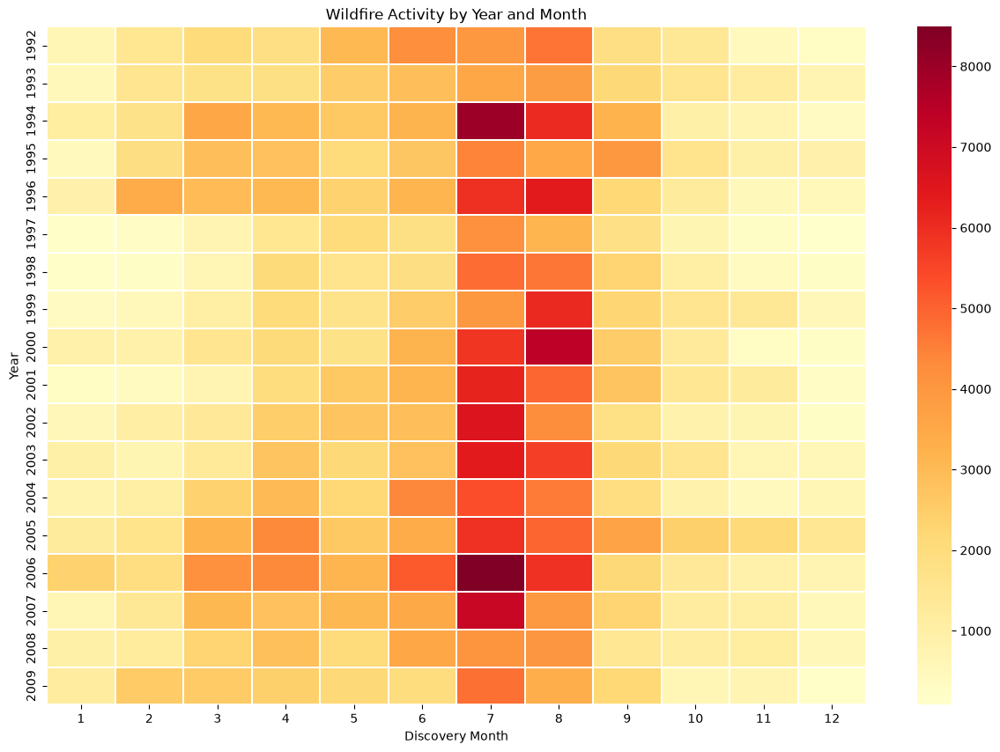

In [42]:
# Extract temporal features from discovery date
df['DISCOVERY_MONTH'] = df['DISCOVERY_DATE'].dt.month
df['DISCOVERY_YEAR'] = df['DISCOVERY_DATE'].dt.year
df['DISCOVERY_DAY'] = df['DISCOVERY_DATE'].dt.day
df['DISCOVERY_WEEK'] = df['DISCOVERY_DATE'].dt.isocalendar().week
df['DISCOVERY_QUARTER'] = df['DISCOVERY_DATE'].dt.quarter
df['DISCOVERY_DAY_OF_WEEK'] = df['DISCOVERY_DATE'].dt.dayofweek

# Optional: Create readable month names
df['DISCOVERY_MONTH_NAME'] = df['DISCOVERY_DATE'].dt.month_name()

# Verify
print(df[['DISCOVERY_DATE', 'DISCOVERY_MONTH',
          'DISCOVERY_MONTH_NAME']].head())
year_month = df.pivot_table(
    index='FIRE_YEAR',
    columns='DISCOVERY_MONTH',
    values='OBJECTID',
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(15, 10))

sns.heatmap(
    year_month,
    cmap='YlOrRd',
    linewidths=0.2
)

plt.title('Wildfire Activity by Year and Month')
plt.xlabel('Discovery Month')
plt.ylabel('Year')
plt.show()

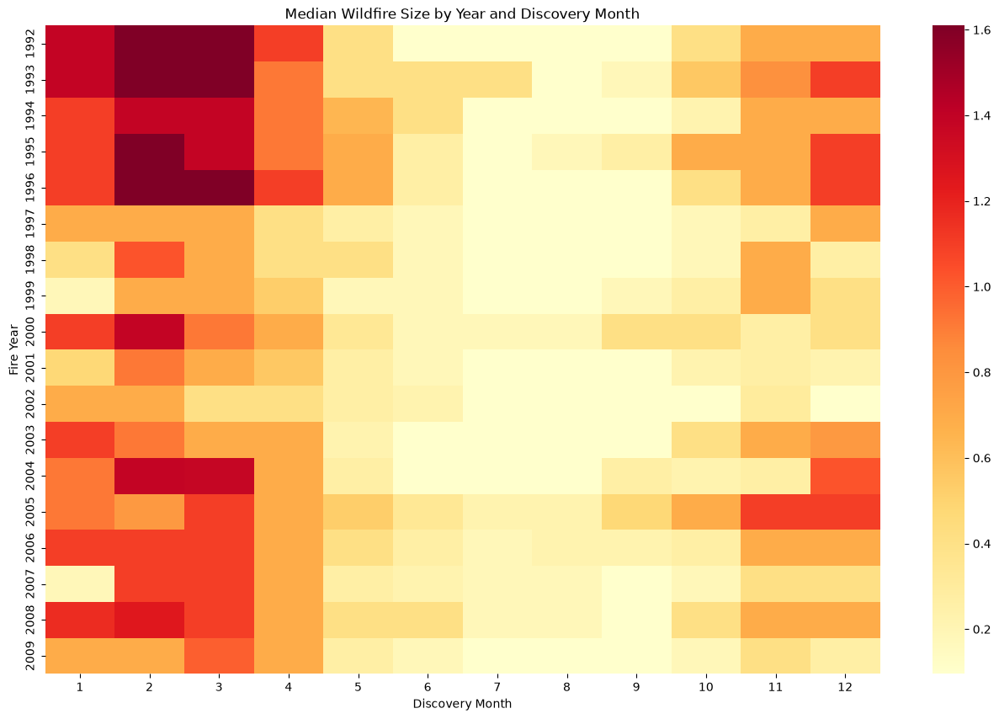

In [39]:
year_month_size = df.pivot_table(
    index='FIRE_YEAR',
    columns='DISCOVERY_MONTH',
    values='FIRE_SIZE',
    aggfunc='median'
)

plt.figure(figsize=(16, 10))

sns.heatmap(
    np.log1p(year_month_size),
    cmap='YlOrRd',
    annot=False
)

plt.title('Median Wildfire Size by Year and Discovery Month')
plt.xlabel('Discovery Month')
plt.ylabel('Fire Year')
plt.show()

Temporal Analysis:

The charts of Wildfire Activity by Year and Month and Median Wildfire Size by Year and Discovery Month show that while there are more wildfires reported in the summer, there are larger wildfires in terms of acreage burned in the winter. This might suggest that there is a difference in how fires are started versus what fires are harder to contain. It might also suggest something about how fire prevention resources are allocated depending on the season. 

The data also shows that in winters of 1992-1996, fires burned larger amounts of acreage, but that trend decreased after 1997. This might reflect a potential change in fire prevention decision making strategies or environmental factors over time. This is something important to consider when building our model, that evaluating the model with temporally separated data will determine whether historical fire patterns generalize to later fires.

Supervised Learning Problem Statement

Background/Significance
    Wildfires have the potential to devastate human communities by threatening lives, destroying property, polluting water and air, and damaging cardiovascular and respiratory health. As global wildfire economic losses increase, being able to predict size of fires based on information about location, time of year and ignition factors will be valuable information to help fire preventers make decisions and contain fires.

EDA findings: 
    
    
Objective:
    The objective of the supervised learning portion of this project is to develop a binary classification model that predicts whether a wildfire will be large in size based on the features available at ignition time. This includes ignition cause, time of year, and location.

Target Variable:
    For this objective, we will use a binary target of 0 = not large, and 1 = large to describe large fires that would be in the 95th percentile or above of fires that occurred before the prediction based on acres burned from 1992 (the beginning of the dataset) - the end of the prediction period. This threshold will be rolling to prevent leakage when attempting to predict fire size from instances in the middle of the time period. This was chosen over using the preexisting FIRE_CLASS classifications given by the FPA to make the separation between large and not large more balanced and more meaningful. It defines a fire as large relative to all the fires that happened before it, so the acreage threshold will change over time.

Descriptor Variables:
    Variables that will not be used to make predictions but describe the recorded fires will include FIRE_SIZE and FIRE_DURATION_DAYS.

Justification: 
    Doing binary classification for this problem is better than multi-class classification because of the distribution of fire records. Fire containment records are right skewed, meaning the majority of fires are contained on the day of discovery and cause less damage, while the largest of the fires require additional resources to handle. Large fires have the potential to be devastating compared to small fires, so predicting whether or not a fire will become large is sufficient when it comes to giving fire-prevention decision information. Fire prediction should prioritize recall over other metrics to ensure that any potential large fires can be accounted for. 

# Spatial Sweep and Unsupervised Problem Framing

*Run from the next cell down ("Run Selected Cell and All Below"). This section reloads the full table itself, so it does not depend on `df` from the cells above.*

This section covers the spatial EDA sweep, the coordinate reporting artifacts, and the framing for the unsupervised problem (fire regime clustering).

It loads the full `Fires` table with **no row limit and no NULL filter**. The `df` above keeps only the first 500k rows that have a containment date, which is ordered by OBJECTID and so over-represents certain years and source systems. Maps of the whole country need every fire.

Sections:
1. Load and derive columns
2. Reporting artifact: coordinate precision and stacked coordinates
3. Spatial density and regional profile maps (grid binned, no raw point overplotting)
4. Cell level fire regime features
5. Preliminary clustering viability
6. Unsupervised problem formulation

In [9]:
##------------Spatial section: config and load------------

import os
import sqlite3
from contextlib import closing

import numpy as np
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

DATA_DIR = os.path.join("wildfire_7th_edition_data", "Data")
DB_PATH = os.path.join(DATA_DIR, "FPA_FOD_20260615.sqlite")

GRID_RES = 0.5            # grid cell size in degrees (about 55 km north-south)
MIN_FIRES_PER_CELL = 30   # cells with fewer fires give noisy profiles and are dropped from clustering
LARGE_FIRE_ACRES = 300    # size class E and above
RANDOM_STATE = 42

SPATIAL_COLS = [
    "OBJECTID", "FIRE_YEAR", "DISCOVERY_DOY", "DISCOVERY_TIME", "FIRE_SIZE",
    "LATITUDE", "LONGITUDE", "OWNER_DESCR", "STATE", "FIPS_CODE",
    "NWCG_REPORTING_AGENCY", "SOURCE_SYSTEM_TYPE", "NWCG_CAUSE_CLASSIFICATION",
]


def load_fires(db_path, cols):
    """Load the selected columns for every fire. No LIMIT and no NULL filter, so missingness stays visible."""
    query = f"SELECT {', '.join(cols)} FROM Fires"
    with closing(sqlite3.connect(db_path)) as conn:
        return pd.read_sql_query(query, conn)


fires_raw = load_fires(DB_PATH, SPATIAL_COLS)
print(f"Loaded {len(fires_raw):,} fires x {fires_raw.shape[1]} columns")

Loaded 2,661,383 fires x 13 columns


In [34]:
##------------Derived columns used throughout this section------------

def add_derived_columns(df):
    out = df.copy()

    # Discovery hour from HHMM. The column is text with blanks, so coerce and validate.
    t = pd.to_numeric(out["DISCOVERY_TIME"], errors="coerce")
    hour, minute = t // 100, t % 100
    valid_time = hour.between(0, 23) & minute.between(0, 59)
    out["DISC_HOUR"] = hour.where(valid_time)

    # Weekday rebuilt from FIRE_YEAR + DISCOVERY_DOY, so it does not depend on how DISCOVERY_DATE is stored.
    year_str = out["FIRE_YEAR"].astype("Int64").astype(str)
    doy_str = out["DISCOVERY_DOY"].astype("Int64").astype(str).str.zfill(3)
    dates = pd.to_datetime(year_str + doy_str, format="%Y%j", errors="coerce")
    out["IS_WEEKEND"] = (dates.dt.dayofweek >= 5).astype(float).where(dates.notna())

    # Size: log scale because FIRE_SIZE is extremely heavy tailed.
    out["LOG_SIZE"] = np.log10(out["FIRE_SIZE"].clip(lower=0.01))
    out["IS_LARGE"] = out["FIRE_SIZE"] >= LARGE_FIRE_ACRES

    # Grid cell assignment, stored as the cell center.
    out["CELL_LAT"] = np.floor(out["LATITUDE"] / GRID_RES) * GRID_RES + GRID_RES / 2
    out["CELL_LON"] = np.floor(out["LONGITUDE"] / GRID_RES) * GRID_RES + GRID_RES / 2
    return out


fires = add_derived_columns(fires_raw)

print(f"Valid discovery hour:  {fires['DISC_HOUR'].notna().mean():.1%} of fires")
print(f"Large fires (>= {LARGE_FIRE_ACRES} ac): {fires['IS_LARGE'].mean():.2%} of fires")
print(f"Missing lat/lon:       {fires[['LATITUDE', 'LONGITUDE']].isna().any(axis=1).mean():.2%} of fires")
print(f"Distinct {GRID_RES} deg cells: {fires.groupby(['CELL_LAT', 'CELL_LON']).ngroups:,}")

Valid discovery hour:  68.8% of fires
Large fires (>= 300 ac): 1.38% of fires
Missing lat/lon:       0.00% of fires
Distinct 0.5 deg cells: 4,428


## 2. Reporting Artifact: Coordinate Precision by Agency and Stacked Points

This extends the coordinate check above to the full table and breaks it down by reporting agency, to show *who* reports approximate locations. Many records are not geolocated to the ignition point. Some agencies report coordinates rounded to 0 or 1 decimal places (roughly 11 to 110 km of uncertainty), and some records are placed at a county or township centroid. Both show up as many fires sharing the exact same coordinate.

This matters for both problems: rounded or stacked points inflate density at artificial locations and can make clusters follow reporting conventions instead of real fire behavior.

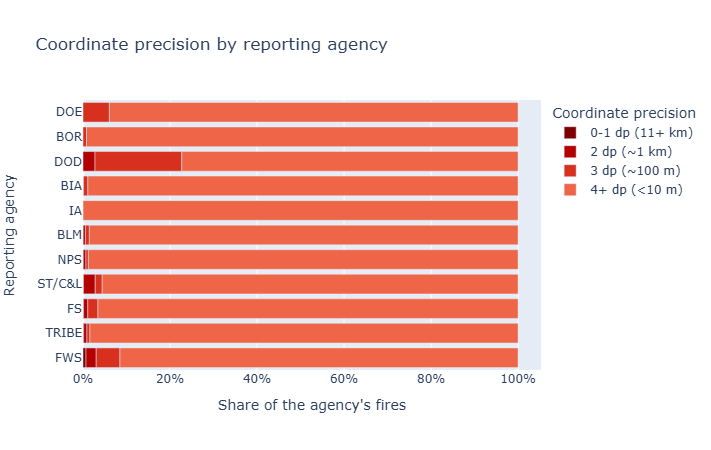

COORD_PRECISION
0-1 dp (11+ km)     0.1%
2 dp (~1 km)        2.2%
3 dp (~100 m)       1.6%
4+ dp (<10 m)      96.1%
Name: proportion, dtype: object


In [36]:
##------------Artifact 1a: coordinate decimal precision by reporting agency------------

def decimal_places(x, max_dp=6):
    """Smallest number of decimal places that represents each value (max_dp + 1 means 'more than max_dp')."""
    x = np.asarray(x, dtype=float)
    dp = np.full(x.shape, max_dp + 1)
    for d in range(max_dp, -1, -1):
        scaled = x * 10**d
        dp = np.where(np.isclose(scaled, np.round(scaled), rtol=0, atol=1e-6), d, dp)
    return dp


coord_dp = np.maximum(decimal_places(fires["LATITUDE"]), decimal_places(fires["LONGITUDE"]))
precision_bins = pd.cut(
    coord_dp, bins=[-1, 1, 2, 3, 100],
    labels=["0-1 dp (11+ km)", "2 dp (~1 km)", "3 dp (~100 m)", "4+ dp (<10 m)"],
)
fires["COORD_PRECISION"] = precision_bins

prec_by_agency = (
    fires.assign(COORD_PRECISION=fires["COORD_PRECISION"].astype(str))
    .groupby("NWCG_REPORTING_AGENCY")["COORD_PRECISION"]
    .value_counts(normalize=True)
    .rename("share")
    .reset_index()
)
agency_order = (
    prec_by_agency[prec_by_agency["COORD_PRECISION"] == "0-1 dp (11+ km)"]
    .sort_values("share")["NWCG_REPORTING_AGENCY"].tolist()
)

fig = px.bar(
    prec_by_agency, x="share", y="NWCG_REPORTING_AGENCY", color="COORD_PRECISION",
    orientation="h",
    category_orders={"NWCG_REPORTING_AGENCY": agency_order,
                     "COORD_PRECISION": list(precision_bins.categories)},
    color_discrete_sequence=px.colors.sequential.OrRd_r,
    title="Coordinate precision by reporting agency",
    labels={"share": "Share of the agency's fires", "NWCG_REPORTING_AGENCY": "Reporting agency",
            "COORD_PRECISION": "Coordinate precision"},
)
fig.update_layout(xaxis_tickformat=".0%", height=450)
fig.show()

print(fires["COORD_PRECISION"].value_counts(normalize=True).sort_index().map("{:.1%}".format))

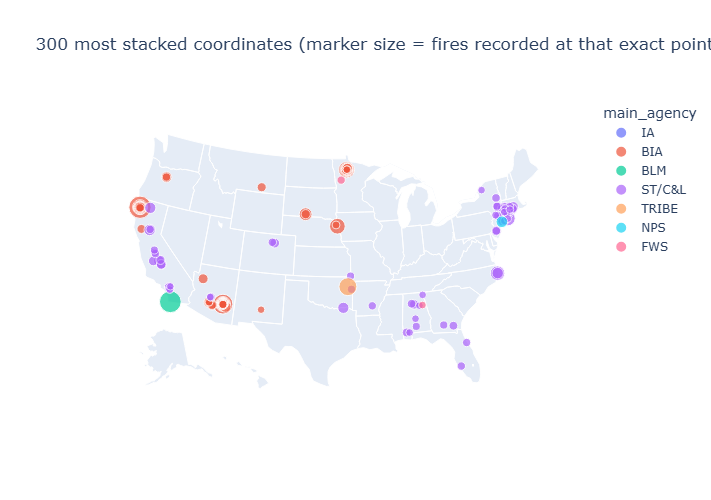

Fires at a coordinate shared by 10+ fires: 3.3%


,LATITUDE,LONGITUDE,fires_at_point,state,n_counties,main_agency
0,17.970539,-66.246414,571,PR,0,IA
1,17.993565,-66.386131,384,PR,0,IA
2,41.066500,-123.684500,355,CA,0,BIA
3,17.976648,-66.114357,352,PR,0,IA
4,32.584800,-116.834700,336,CA,0,BLM
5,17.958364,-66.172852,326,PR,0,IA
6,18.036682,-66.254295,282,PR,0,IA
7,33.335300,-110.451800,281,AZ,0,BIA
8,41.485930,-73.050663,253,CT,1,ST/C&L
9,17.970869,-66.368584,239,PR,0,IA


In [69]:
##------------Artifact 1b: where the stacked coordinates are (full table)------------

point_counts = fires.groupby(["LATITUDE", "LONGITUDE"]).size().rename("fires_at_point")
# drop first so this cell can be rerun safely
fires = fires.drop(columns="fires_at_point", errors="ignore").join(point_counts, on=["LATITUDE", "LONGITUDE"])

# The most stacked points: these are usually county or administrative centroids, not ignition points.
# Pick the 300 most stacked coordinates first, then summarize only those fires (fast on the full table).
top_coords = point_counts.nlargest(300).reset_index()[["LATITUDE", "LONGITUDE"]]
top_fires = fires.merge(top_coords, on=["LATITUDE", "LONGITUDE"])
top_points = (
    top_fires.groupby(["LATITUDE", "LONGITUDE"])
    .agg(fires_at_point=("OBJECTID", "size"),
         state=("STATE", lambda s: s.mode().iat[0] if s.notna().any() else None),
         n_counties=("FIPS_CODE", "nunique"),
         main_agency=("NWCG_REPORTING_AGENCY", lambda s: s.mode().iat[0] if s.notna().any() else None))
    .sort_values("fires_at_point", ascending=False)
    .reset_index()
)

fig = px.scatter_geo(
    top_points, lat="LATITUDE", lon="LONGITUDE", size="fires_at_point", color="main_agency",
    scope="usa", hover_data=["state", "fires_at_point", "n_counties"],
    title="300 most stacked coordinates (marker size = fires recorded at that exact point)",
)
fig.update_layout(height=500)
fig.show()

print(f"Fires at a coordinate shared by 10+ fires: {(fires['fires_at_point'] >= 10).mean():.1%}")
top_points.head(15)

**Observations:**
- Coordinate rounding is rare in the full table: 0.1% of fires have 0-1 decimal places, 2.2% have 2, 1.6% have 3, and 96.1% have 4 or more. It is concentrated in a few agencies. DOD reports about 23% of its fires with 3 or fewer decimals, FWS about 9% and DOE about 6%, while BLM, NPS, BIA and IA report almost everything at 4+ decimals.
- Stacking is the larger artifact: 3.3% of fires sit on a coordinate shared by 10 or more fires. The most stacked points are in Puerto Rico (reported by IA, up to 571 fires at one point), on tribal land (BIA points in northern California, Arizona and the northern Plains, and a TRIBE point in Oklahoma with 230 fires), and in state-reported clusters across the Northeast, California and the Southeast. 14 of the top 15 points have no county code, so they are reference points for a reporting unit, not ignition locations.
- **Implication:** fine-resolution spatial features would partly learn reporting conventions. Aggregating to a 0.5 degree grid absorbs this noise, and per-cell precision and owner-missing shares are kept as diagnostics to test whether clusters track reporting instead of fire behavior.

## 3. Spatial Sweep: Grid Binned Maps

Raw point maps of 2.6M fires overplot badly, so every map below aggregates fires into 0.5 degree cells and colors each cell by a summary statistic. The same cells become the unit of analysis for the unsupervised problem.

In [40]:
##------------Per-cell summary for mapping------------

def circular_peak(values, period):
    """Circular mean of a cyclic variable (day of year, hour). Returns the peak position on the original scale."""
    ang = 2 * np.pi * values / period
    s, c = np.nanmean(np.sin(ang)), np.nanmean(np.cos(ang))
    return (np.arctan2(s, c) % (2 * np.pi)) * period / (2 * np.pi)


n_years = fires["FIRE_YEAR"].max() - fires["FIRE_YEAR"].min() + 1
cause = fires["NWCG_CAUSE_CLASSIFICATION"].fillna("").str.lower()
fires["IS_NATURAL"] = np.where(cause.str.startswith("natural"), 1.0,
                               np.where(cause.str.startswith("human"), 0.0, np.nan))

cell_map = (
    fires.dropna(subset=["CELL_LAT", "CELL_LON"])
    .groupby(["CELL_LAT", "CELL_LON"])
    .agg(n_fires=("OBJECTID", "size"),
         natural_share=("IS_NATURAL", "mean"),
         large_share=("IS_LARGE", "mean"),
         peak_doy=("DISCOVERY_DOY", lambda v: circular_peak(v - 1, 365.25) + 1))
    .reset_index()
)
cell_map["fires_per_year"] = cell_map["n_fires"] / n_years
cell_map["log10_fires_per_year"] = np.log10(cell_map["fires_per_year"])
dense = cell_map[cell_map["n_fires"] >= MIN_FIRES_PER_CELL]


def plot_cells(cells, color, title, scale="YlOrRd", range_color=None, hover=None, tickformat=None):
    fig = px.scatter_geo(
        cells, lat="CELL_LAT", lon="CELL_LON", color=color, scope="usa",
        color_continuous_scale=scale, range_color=range_color,
        hover_data=hover or ["n_fires"], title=title,
    )
    fig.update_traces(marker=dict(size=5, symbol="square", line_width=0))
    fig.update_layout(height=500, margin=dict(l=0, r=0, t=50, b=0))
    if tickformat:
        fig.update_coloraxes(colorbar_tickformat=tickformat)
    fig.show()


print(f"{len(cell_map):,} cells with any fire, {len(dense):,} cells with >= {MIN_FIRES_PER_CELL} fires "
      f"(covering {dense['n_fires'].sum() / cell_map['n_fires'].sum():.1%} of fires)")

4,428 cells with any fire, 3,279 cells with >= 30 fires (covering 99.6% of fires)


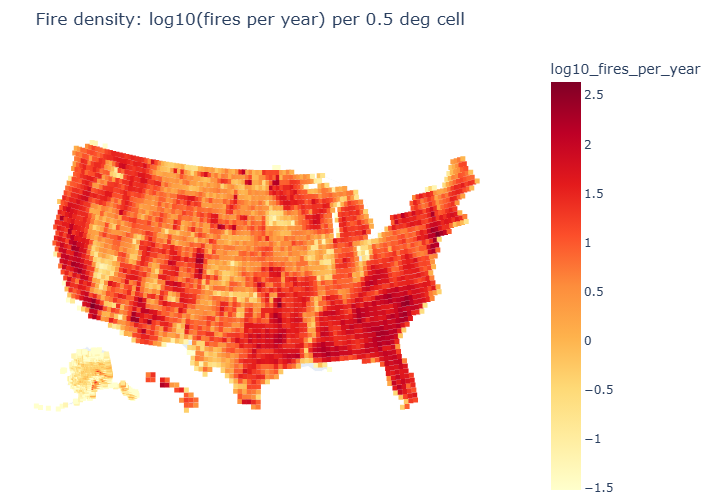

In [41]:
##------------Map 1: fire density------------
plot_cells(cell_map, "log10_fires_per_year",
           f"Fire density: log10(fires per year) per {GRID_RES} deg cell",
           hover=["n_fires", "fires_per_year"])

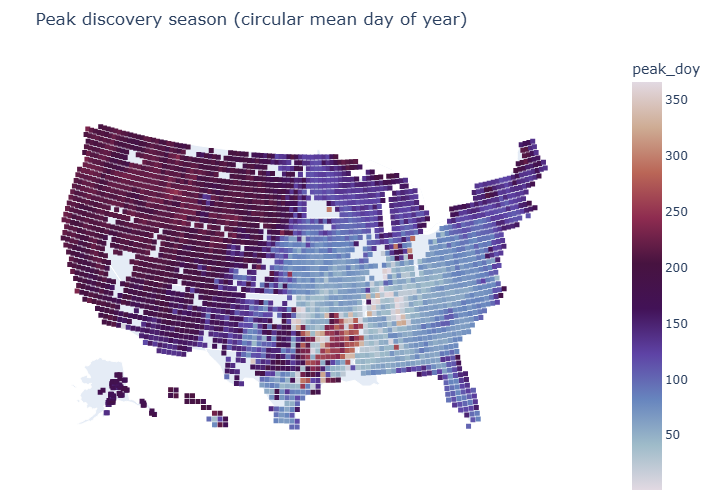

In [42]:
##------------Map 2: peak discovery season (circular mean of day of year)------------
plot_cells(dense, "peak_doy", "Peak discovery season (circular mean day of year)",
           scale=px.colors.cyclical.Twilight, range_color=(1, 366), hover=["n_fires", "peak_doy"])

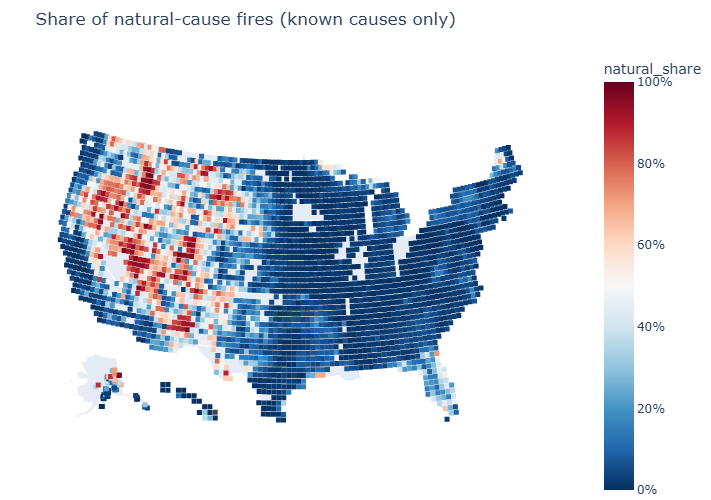

In [43]:
##------------Map 3: natural (lightning) share among fires with a known cause------------
plot_cells(dense, "natural_share", "Share of natural-cause fires (known causes only)",
           scale="RdBu_r", range_color=(0, 1), hover=["n_fires", "natural_share"], tickformat=".0%")

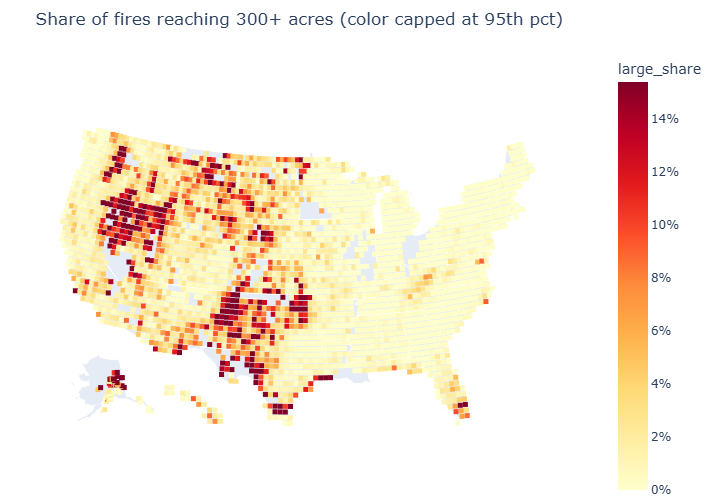

In [44]:
##------------Map 4: large fire rate (>= 300 acres), related to the supervised target------------
cap = dense["large_share"].quantile(0.95)
plot_cells(dense, "large_share", f"Share of fires reaching {LARGE_FIRE_ACRES}+ acres (color capped at 95th pct)",
           range_color=(0, cap), hover=["n_fires", "large_share"], tickformat=".0%")

**Observations:**
- **Density:** fire counts per cell are highest across the Southeast (east Texas and Oklahoma through the Carolinas and Florida), the New York/New Jersey area, and pockets of California and Arizona. The interior West, northern Plains and Alaska are sparse. Parts of the Midwest and central Plains are pale or empty with edges that follow state lines, which points to differences in state reporting rather than fire activity.
- **Season:** the eastern regime peaks in early April (median peak around day 95), while the federal Western regime peaks in late July (around day 207). The fire calendar is strongly regional.
- **Cause:** natural fires make up 60-80%+ of known causes across the interior West (Montana, Idaho, Nevada, Utah, Arizona, New Mexico) and interior Alaska, while nearly every cell east of the Plains is under 10%. Florida is the main eastern exception at roughly 20-40%, and Pacific coast cells are mostly human caused despite being in the West. Overall, 14.9% of known-cause fires are natural.
- **Large fires:** 1.38% of all fires reach 300+ acres. The rate is highest in the Great Basin (southern Idaho, eastern Oregon, Nevada), the southern High Plains (west Texas, the Oklahoma panhandle, southwest Kansas) and Alaska, often 14%+ of a cell's fires, and near 0% across most of the East. Density and severity are decoupled: the densest regions mostly produce small fires. The supervised target uses a rolling 95th-percentile size threshold instead of this fixed 300-acre cutoff, but the same geography should drive it, which supports location as a strong predictor for the large-fire classifier.

## 4. Cell Level Fire Regime Features (Unsupervised Feature Space)

Each grid cell with at least 30 fires becomes one observation. Features describe how fire behaves in that cell. **Cause labels and raw lat/lon are deliberately excluded**: cause is held out to validate the clusters afterward, and leaving out location means any spatially coherent clusters emerge from fire behavior alone.

Preprocessing choices:
- **Cyclical encoding:** day of year and discovery hour are converted to sine/cosine circular means, so Dec 31 and Jan 1 (or 23:00 and 00:00) are close together. Seasonal concentration (mean resultant length) captures whether fires cluster in a short season or are spread across the year.
- **Heavy tails:** fire counts and sizes are log transformed.
- **High-cardinality categoricals:** `OWNER_DESCR` (about 18 raw values) is grouped into federal, tribal and nonfederal (the raw data has a combined "STATE OR PRIVATE" value, so state and private cannot be separated), then aggregated to per-cell shares among fires with a known owner instead of one-hot encoding each fire. "MISSING/NOT SPECIFIED" is kept out of the features and tracked as a reporting diagnostic.
- **Standardization:** all features are z-scored before clustering so no single unit dominates the distance.

In [47]:
##------------Build the per-cell feature matrix------------

# OWNER_DESCR values in the 7th edition. "STATE OR PRIVATE" cannot be split, so state, local and private
# land are grouped as nonfederal. "MISSING/NOT SPECIFIED" is a reporting artifact, so it is kept as a
# diagnostic (owner_missing_share) and the ownership features are shares among fires with a known owner.
OWNER_GROUPS = {
    "federal": ["USFS", "BLM", "NPS", "FWS", "BOR", "DOD", "DOE", "OTHER FEDERAL", "UNDEFINED FEDERAL"],
    "tribal": ["BIA", "TRIBAL"],
    "nonfederal": ["STATE", "COUNTY", "MUNICIPAL/LOCAL", "PRIVATE", "STATE OR PRIVATE"],
}

FEATURE_COLS = [
    "log_fires_per_year", "doy_peak_sin", "doy_peak_cos", "doy_concentration",
    "hour_peak_sin", "hour_peak_cos", "hour_concentration",
    "med_log_size", "large_share", "weekend_share", "interannual_cv",
    "own_federal", "own_tribal", "own_nonfederal",
]
VALIDATION_COLS = ["natural_share", "n_fires", "hour_known_share", "low_precision_share", "owner_missing_share"]


def build_cell_features(df, min_fires):
    d = df.dropna(subset=["CELL_LAT", "CELL_LON"]).copy()

    doy_ang = 2 * np.pi * (d["DISCOVERY_DOY"] - 1) / 365.25
    d["doy_s"], d["doy_c"] = np.sin(doy_ang), np.cos(doy_ang)
    hour_ang = 2 * np.pi * d["DISC_HOUR"] / 24
    d["hour_s"], d["hour_c"] = np.sin(hour_ang), np.cos(hour_ang)
    d["hour_known"] = d["DISC_HOUR"].notna()
    d["low_precision"] = d["COORD_PRECISION"] == "0-1 dp (11+ km)"

    owner = d["OWNER_DESCR"].fillna("").str.upper().str.strip()
    known_owner = pd.Series(False, index=d.index)
    for group, values in OWNER_GROUPS.items():
        d[f"own_{group}"] = owner.isin(values).astype(float)
        known_owner |= owner.isin(values)
    unmapped = owner[~known_owner & (owner != "MISSING/NOT SPECIFIED")].value_counts()
    if len(unmapped):
        print("OWNER_DESCR values not in any group (check OWNER_GROUPS):", unmapped.head(10).to_dict())
    d["owner_missing"] = ~known_owner
    for group in OWNER_GROUPS:
        d[f"own_{group}"] = d[f"own_{group}"].where(known_owner)   # share among known owners only

    keys = ["CELL_LAT", "CELL_LON"]
    cells = d.groupby(keys).agg(
        n_fires=("OBJECTID", "size"),
        doy_s=("doy_s", "mean"), doy_c=("doy_c", "mean"),
        hour_s=("hour_s", "mean"), hour_c=("hour_c", "mean"),
        hour_known_share=("hour_known", "mean"),
        med_log_size=("LOG_SIZE", "median"),
        large_share=("IS_LARGE", "mean"),
        weekend_share=("IS_WEEKEND", "mean"),
        natural_share=("IS_NATURAL", "mean"),
        low_precision_share=("low_precision", "mean"),
        owner_missing_share=("owner_missing", "mean"),
        **{f"own_{g}": (f"own_{g}", "mean") for g in OWNER_GROUPS},
    )

    # Year to year variability: coefficient of variation of annual counts, with zero-fire years included.
    years = range(int(d["FIRE_YEAR"].min()), int(d["FIRE_YEAR"].max()) + 1)
    yearly = d.groupby(keys + ["FIRE_YEAR"]).size().unstack(fill_value=0).reindex(columns=years, fill_value=0)
    cells["interannual_cv"] = yearly.std(axis=1) / yearly.mean(axis=1)

    cells["log_fires_per_year"] = np.log10(cells["n_fires"] / len(years))

    # Circular means -> peak direction (unit sin/cos) + concentration (resultant length, 0 = spread, 1 = one spike).
    for name in ["doy", "hour"]:
        s, c = cells[f"{name}_s"], cells[f"{name}_c"]
        r = np.sqrt(s**2 + c**2)
        cells[f"{name}_concentration"] = r
        cells[f"{name}_peak_sin"] = s / r
        cells[f"{name}_peak_cos"] = c / r
    # Cells with no valid discovery times get a neutral hour profile.
    cells[["hour_peak_sin", "hour_peak_cos", "hour_concentration"]] = (
        cells[["hour_peak_sin", "hour_peak_cos", "hour_concentration"]].fillna(0)
    )
    # Cells where no fire has a known owner get the national average ownership mix.
    own_cols = [f"own_{g}" for g in OWNER_GROUPS]
    cells[own_cols] = cells[own_cols].fillna(cells[own_cols].mean())
    cells["peak_doy"] = (np.arctan2(cells["doy_s"], cells["doy_c"]) % (2 * np.pi)) * 365.25 / (2 * np.pi) + 1

    cells = cells[cells["n_fires"] >= min_fires].reset_index()
    return cells


cells = build_cell_features(fires, MIN_FIRES_PER_CELL)
print(f"Feature matrix: {len(cells):,} cells x {len(FEATURE_COLS)} features")
cells[FEATURE_COLS].describe().T.round(3)

OWNER_DESCR values not in any group (check OWNER_GROUPS): {'FOREIGN': 18}
Feature matrix: 3,279 cells x 14 features


,count,mean,std,min,25%,50%,75%,max
log_fires_per_year,3279.0,1.053,0.560,-0.041,0.609,1.047,1.481,2.633
doy_peak_sin,3279.0,0.259,0.606,-1.000,-0.364,0.378,0.865,1.000
doy_peak_cos,3279.0,-0.446,0.606,-1.000,-0.924,-0.778,0.072,1.000
doy_concentration,3279.0,0.499,0.229,0.005,0.317,0.498,0.695,0.975
hour_peak_sin,3279.0,-0.590,0.240,-1.000,-0.711,-0.616,-0.522,1.000
hour_peak_cos,3279.0,-0.750,0.174,-1.000,-0.849,-0.784,-0.698,0.998
hour_concentration,3279.0,0.614,0.122,0.000,0.545,0.627,0.695,1.000
med_log_size,3279.0,-0.147,0.664,-2.000,-0.699,0.000,0.301,2.778
large_share,3279.0,0.034,0.059,0.000,0.001,0.011,0.038,0.610
weekend_share,3279.0,0.302,0.049,0.049,0.276,0.302,0.330,0.545


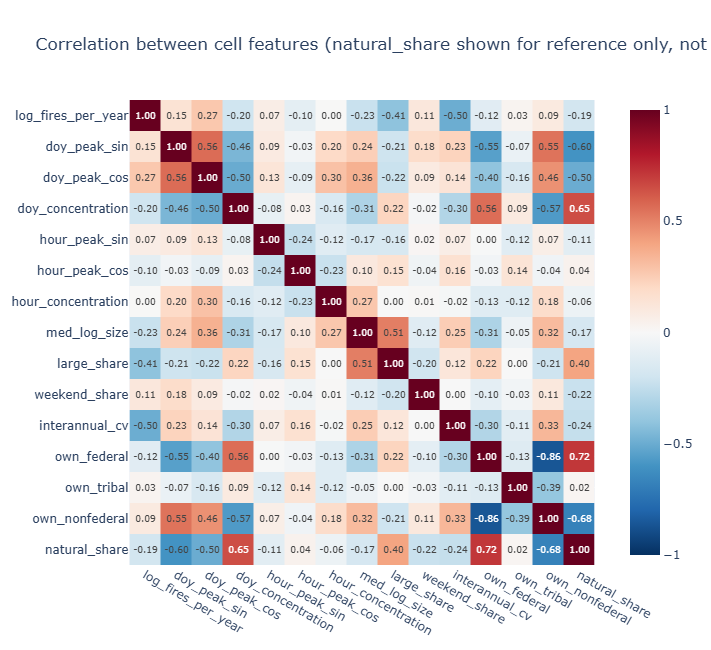

In [48]:
##------------Feature correlation (redundancy check before clustering)------------
corr = cells[FEATURE_COLS + ["natural_share"]].corr()
fig = px.imshow(corr, color_continuous_scale="RdBu_r", zmin=-1, zmax=1, text_auto=".2f",
                title="Correlation between cell features (natural_share shown for reference only, not a feature)")
fig.update_layout(height=650)
fig.show()

## 5. Preliminary Clustering Viability

A quick K-Means sweep on the standardized feature matrix, to confirm the cells have real cluster structure before committing to this problem. The full pipeline (k selection with elbow, silhouette, Davies-Bouldin and GMM BIC, sensitivity to grid size, era comparison) comes in Milestone 3.

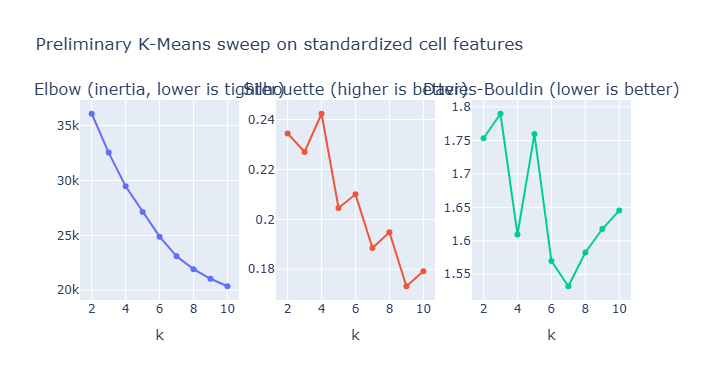

Preview k = 4


,k,inertia,silhouette,davies_bouldin
0,2,36064.962,0.234,1.753
1,3,32526.150,0.227,1.790
2,4,29458.290,0.242,1.609
3,5,27125.987,0.205,1.759
4,6,24875.232,0.210,1.570
5,7,23089.149,0.189,1.532
6,8,21917.092,0.195,1.583
7,9,21043.725,0.173,1.618
8,10,20362.079,0.179,1.645


In [50]:
##------------K-Means sweep: elbow, silhouette, Davies-Bouldin------------

X = StandardScaler().fit_transform(cells[FEATURE_COLS])

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_)})
sweep = pd.DataFrame(rows)

fig = make_subplots(rows=1, cols=3, subplot_titles=[
    "Elbow (inertia, lower is tighter)", "Silhouette (higher is better)", "Davies-Bouldin (lower is better)"])
for i, col in enumerate(["inertia", "silhouette", "davies_bouldin"], start=1):
    fig.add_scatter(x=sweep["k"], y=sweep[col], mode="lines+markers", showlegend=False, row=1, col=i)
    fig.update_xaxes(title_text="k", row=1, col=i)
fig.update_layout(height=380, title="Preliminary K-Means sweep on standardized cell features")
fig.show()

# k = 2 usually wins silhouette trivially (West vs East), so the preview uses the best k from 3 upward.
PRELIM_K = int(sweep.loc[sweep["k"] >= 3].sort_values("silhouette", ascending=False)["k"].iat[0])
print(f"Preview k = {PRELIM_K}")
sweep.round(3)

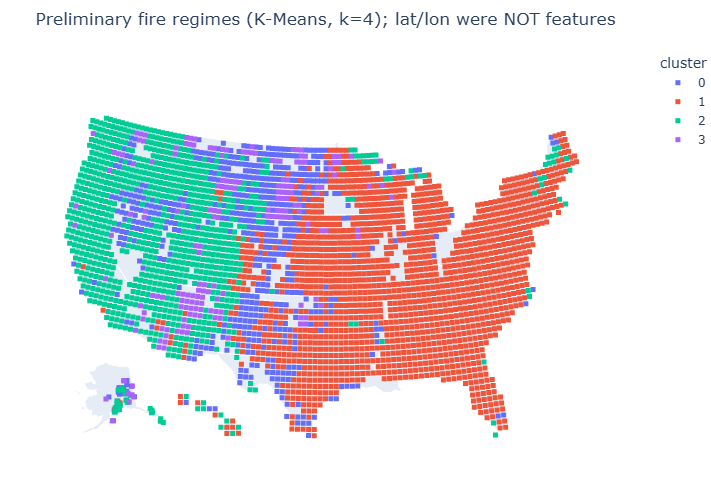

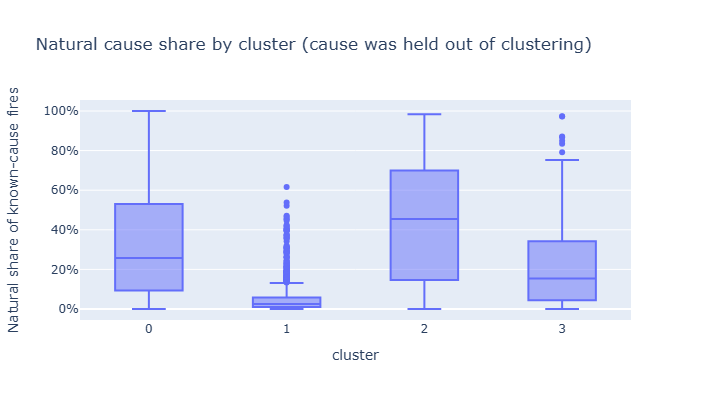

,cells,fires,fires_per_year_median,peak_doy,doy_concentration,med_log_size,large_share,own_federal,natural_share,low_precision_share
cluster,,,,,,,,,,
0,540,61122,2.545,192.027,0.545,0.566,0.117,0.254,0.325,0.002
1,1614,1718634,18.712,95.486,0.363,-0.012,0.011,0.064,0.048,0.001
2,941,698241,12.667,207.357,0.691,-0.756,0.028,0.611,0.442,0.001
3,184,172565,13.363,183.747,0.567,-0.308,0.027,0.081,0.223,0.000


In [51]:
##------------Preview: where the clusters fall, and whether they recover cause without seeing it------------

km = KMeans(n_clusters=PRELIM_K, n_init=10, random_state=RANDOM_STATE).fit(X)
cells["cluster"] = km.labels_.astype(str)
cluster_order = sorted(cells["cluster"].unique(), key=int)

fig = px.scatter_geo(cells, lat="CELL_LAT", lon="CELL_LON", color="cluster", scope="usa",
                     category_orders={"cluster": cluster_order},
                     hover_data=["n_fires", "natural_share", "peak_doy"],
                     title=f"Preliminary fire regimes (K-Means, k={PRELIM_K}); lat/lon were NOT features")
fig.update_traces(marker=dict(size=5, symbol="square", line_width=0))
fig.update_layout(height=500, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

fig = px.box(cells, x="cluster", y="natural_share", category_orders={"cluster": cluster_order},
             title="Natural cause share by cluster (cause was held out of clustering)",
             labels={"natural_share": "Natural share of known-cause fires"})
fig.update_layout(yaxis_tickformat=".0%", height=400)
fig.show()

profile = cells.groupby("cluster").agg(
    cells=("n_fires", "size"), fires=("n_fires", "sum"),
    fires_per_year_median=("log_fires_per_year", lambda v: 10 ** v.median()),
    peak_doy=("peak_doy", "median"), doy_concentration=("doy_concentration", "mean"),
    med_log_size=("med_log_size", "mean"), large_share=("large_share", "mean"),
    own_federal=("own_federal", "mean"), natural_share=("natural_share", "mean"),
    low_precision_share=("low_precision_share", "mean"),
).loc[cluster_order]
profile.round(3)

In [52]:
##------------Viability summary (numbers to quote in the formulation below)------------
spread = profile["natural_share"]
print(f"Cells retained:              {len(cells):,} ({cells['n_fires'].sum() / len(fires):.1%} of all fires)")
print(f"Best silhouette (k>=3):      {sweep.loc[sweep['k'] >= 3, 'silhouette'].max():.3f} at k={PRELIM_K}")
print(f"Natural share across clusters: {spread.min():.1%} to {spread.max():.1%} (overall {fires['IS_NATURAL'].mean():.1%})")
print(f"Low-precision coordinates:   {(fires['COORD_PRECISION'] == '0-1 dp (11+ km)').mean():.1%} of fires")
print(f"Fires at stacked points:     {(fires['fires_at_point'] >= 10).mean():.1%} share a coordinate with 9+ others")

Cells retained:              3,279 (99.6% of all fires)
Best silhouette (k>=3):      0.242 at k=4
Natural share across clusters: 4.8% to 44.2% (overall 14.9%)
Low-precision coordinates:   0.1% of fires
Fires at stacked points:     3.3% share a coordinate with 9+ others


## 6. Unsupervised Problem Formulation

**Question:** What distinct wildfire regimes exist across the United States, defined by how often fires occur, when in the year and day they are discovered, how large they grow, and who manages the land, and do those regimes recover real ignition patterns without being given cause labels?

**Unit of analysis:** 0.5 degree grid cells with at least 30 fires from 1992 to 2024 (3,279 cells covering 99.6% of all fires).

**Operational features (14, all standardized):**

| Group | Features | Preprocessing |
|---|---|---|
| Activity | log10 fires per year, interannual coefficient of variation | log transform for the heavy tail |
| Season | peak day of year (sin, cos), seasonal concentration | circular mean, preserves the Dec/Jan boundary |
| Time of day | peak discovery hour (sin, cos), diurnal concentration | circular mean, neutral value when times are missing |
| Size | median log10 fire size, share of fires 300+ acres | log transform |
| Weekly | weekend share | proportion |
| Land ownership | federal, tribal, nonfederal shares | raw categories grouped, aggregated to shares among known owners |

**Held out on purpose:** cause labels (used only for validation), raw lat/lon (so spatial coherence must emerge from behavior), containment fields and fire names.

**Algorithms:** K-Means as the primary model and a Gaussian Mixture Model as the comparison. k is justified with elbow, silhouette, Davies-Bouldin and GMM BIC.

**Target insights:**
1. A map of fire regimes and a plain language profile of each one.
2. **Cause recovery:** each regime's natural vs human mix, revealed only after clustering.
3. **Administrative reporting patterns:** whether regime boundaries snap to state lines or track coordinate precision and missing discovery times, which would indicate reporting artifacts rather than ecology.
4. **Historical anomalies:** cells that change regime between 1992-2007 and 2008-2024, and cells far from their cluster centroid.

**Baseline viability from the EDA:**
- The spatial maps show strong, spatially coherent differences in density, cause mix and large fire rate.
- A preliminary K-Means sweep peaks at a silhouette of 0.242 at k = 4, which is also a local minimum of Davies-Bouldin (1.609). Separation is moderate, so regimes grade into each other rather than splitting cleanly. Davies-Bouldin keeps improving to k = 7, so Milestone 3 compares k = 4 to 7 with a GMM and BIC. Even so, the k = 4 clusters form contiguous regions although lat/lon were not features.
- The four preliminary regimes are interpretable:
  - **Cluster 1** (1,614 cells, 1.72M fires): the whole East and eastern Plains. Dense, early April peak, median fire about 1 acre, 5% natural, 6% federal land. Human-caused spring burning.
  - **Cluster 2** (941 cells, 698k fires): the Pacific Northwest, Sierra Nevada and Rocky Mountains. Late July peak, 61% federal land, 44% natural, very small median size. Summer lightning fires on federal land, mostly caught early.
  - **Cluster 0** (540 cells, 61k fires): northern Plains, high desert and south Texas. Sparse (about 2.5 fires per cell per year), but 11.7% reach 300+ acres. Large rangeland fires.
  - **Cluster 3** (184 cells, 173k fires): scattered across the Southwest and northern Plains. Early July peak, mostly nonfederal, 22% natural. The least distinct group and a candidate to merge or split in Milestone 3.
- The natural cause share ranges from 4.8% (cluster 1) to 44.2% (cluster 2) despite cause being held out, so the feature space carries real ignition signal. The correlation matrix shows why: natural share tracks federal land share (r = 0.72) and seasonal concentration (r = 0.65).
- Federal and nonfederal shares are strongly anti-correlated (r = -0.86) because they are compositional, so Milestone 3 drops one of them.
- Coordinate rounding (0.1% of fires) and stacked points (3.3%) are absorbed by the 0.5 degree grid, and their per-cell shares are kept as diagnostics.